In [ ]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.stats import binom, norm

In [ ]:
# El precio justo de un forward es :
S0 = 5000
t = 100
r_t = 0.11567

K_justo = S0 * np.exp(r_t * t/360)
print(K_justo)


5163.261575007652


In [ ]:
# Interpolacion

def interp_lineal(t1,t2,r_t1,r_t2,t):
  r_t = (r_t2 - r_t1) / (t2-t1) * (t-t1) + r_t1
  return r_t

In [ ]:
interp_lineal(90,120,0.115,0.117,100)

0.11566666666666667

In [ ]:
t = [1,30,90,120]
r_t = [0.11,0.112,0.115,0.117]

In [ ]:
r_t_inter = np.interp(100,t,r_t)
print(r_t_inter)

0.11566666666666667


In [ ]:
# El precio justo de un forward es:
t = [1,30,90,120]
r_t = [0.11,0.112,0.115,0.117]

S0 = 5000
T = 100

K_justo = S0 * np.exp(np.interp(T,t,r_t) * T / 360) # /360 dias de un año
print(K_justo)

5163.2567942121095


In [ ]:
np.interp(100,t,r_t)

np.float64(0.11566666666666667)

In [ ]:
r_t_cs = CubicSpline(t,r_t)
r_t_cs(100)

array(0.11558277)

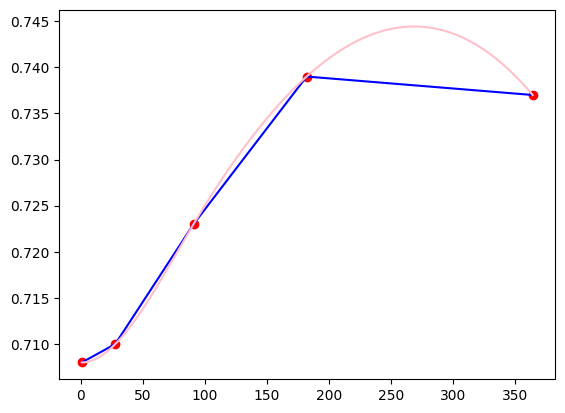

In [ ]:
t = [1,28,91,182,364]
r_t = [0.708,0.71,0.723,0.739,0.737]

x = np.arange(min(t),max(t)+1)
r_t_completa = np.interp(x,t,r_t)
r_t_cs = CubicSpline(t,r_t)

plt.plot(t,r_t,"o", color="red")
plt.plot(x,r_t_completa,color="blue")
plt.plot(x,r_t_cs(x),color="pink")

plt.show()

In [ ]:
# Calcula el precio de un forward en el tiempo t

tiempo = [1,30,90,120]
r_t = [0.11,0.112,0.115,0.117]

S0 = 5000
T = 100

K_justo = S0 * np.exp(np.interp(T,tiempo,r_t) * T / 360) # /360 dias de un año
print(f'el precio justo en t = 0: {K_justo}')

# Dias posteriores t
t = 50
St = 5300
pb = 100
r_t_pb = np.array(r_t) + (pb / 10000)
r_t_pb


p_larga = St - K_justo * np.exp(-np.interp(T-t,tiempo,r_t_pb) * (T-t) / 360) # /360 dias de un año
print(f'el precio de la pos larga en t = {t}: {p_larga}')

p_corta = -St + K_justo * np.exp(-np.interp(T-t,tiempo,r_t_pb) * (T-t) / 360) # /360 dias de un año
print(f'el precio de la pos corta en t = {t}: {p_corta}')



el precio justo en t = 0: 5163.2567942121095
el precio de la pos larga en t = 50: 224.19969160590426
el precio de la pos corta en t = 50: -224.19969160590426


In [ ]:
S0 = 100
k = 95
vol = 0.2
r = 0.11
T = 2
pasos = 2


In [ ]:
dt = T/pasos
u = np.exp(vol*np.sqrt(dt))
d = 1/u
p = (np.exp(r)-d)/(u-d)
q = 1 - p


In [ ]:
prima_call = 0
prima_put = 0
for i in range(pasos+1):
  prima_call += math.comb(pasos,i) * (p**i) * (q**(pasos-i)) * max(S0*(u**i)*(d**(pasos-i))-k,0) * np.exp(-r*T)
  prima_put += math.comb(pasos,i) * (p**i) * (q**(pasos-i)) * max(k-S0*(u**i)*(d**(pasos-i)),0) * np.exp(-r*T)

print(prima_call)
print(prima_put)

25.290473543163458
1.529759349598916


In [ ]:
def funcion1_opcion(S0,k,vol,r,T,pasos,tipo):
  dt = T/pasos
  u = np.exp(vol*np.sqrt(dt))
  d = 1/u
  p = (np.exp(r*dt)-d)/(u-d)
  q = 1 - p

  prima = 0

  if tipo == 'call':
    for i in range(pasos+1):
      prima += math.comb(pasos,i) * (p**i) * (q**(pasos-i)) * max(S0*(u**i)*(d**(pasos-i))-k,0) * np.exp(-r*T)

  if tipo == 'put':
    for i in range(pasos+1):
      prima += math.comb(pasos,i) * (p**i) * (q**(pasos-i)) * max(k-S0*(u**i)*(d**(pasos-i)),0) * np.exp(-r*T)

  return prima



In [ ]:
def funcion2_opcion(S0,k,vol,r,T,pasos,tipo):
  dt = T/pasos
  u = np.exp(vol*np.sqrt(dt))
  d = 1/u
  p = (np.exp(r*dt)-d)/(u-d)
  q = 1 - p
  p2 = (p*u) / np.exp(r*dt)
  m = int(np.log(k/(S0*d**pasos))/np.log(u/d))+1

  prima = 0

  if tipo == 'call':
    prima = S0 * (1 - binom.cdf(m-1, pasos, p2)) - k * np.exp(-r * T) * (1 - binom.cdf(m-1, pasos, p))

  if tipo == 'put':
    prima = k * np.exp(-r * T) * (binom.cdf(m - 1, pasos, p)) - S0 * (binom.cdf(m - 1, pasos, p2))


  return prima

In [ ]:
call = funcion1_opcion(100,95,0.2,0.11,2,2,'call')
put = funcion1_opcion(100,95,0.2,0.11,2,2,'put')

print(f'La prima del call es: {call}')
print(f'La prima del put es: {put}')

La prima del call es: 25.290473543163458
La prima del put es: 1.529759349598916


In [ ]:
call = funcion2_opcion(100,95,0.2,0.11,2,2,'call')
put = funcion2_opcion(100,95,0.2,0.11,2,2,'put')

print(f'La prima del call es: {call}')
print(f'La prima del put es: {put}')

La prima del call es: 25.290473543163458
La prima del put es: 1.5297593495989177


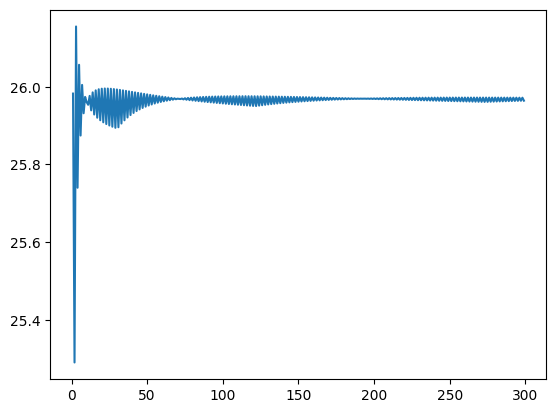

In [ ]:
precios = []

for i in np.arange(1,300):
  precios.append(funcion1_opcion(100,95,0.20,0.11,2,i,'call'))

plt.plot(np.arange(1,300),precios)
plt.show()

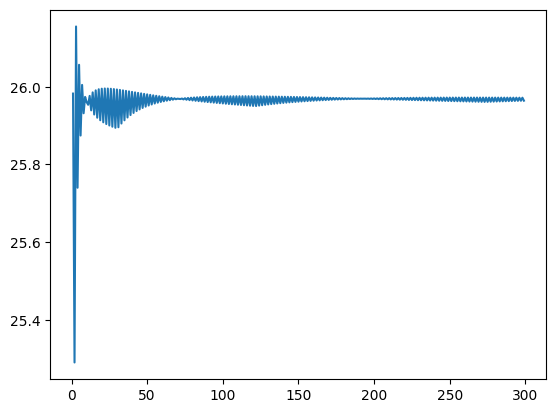

In [ ]:
precios = []

for i in np.arange(1,300):
  precios.append(funcion2_opcion(100,95,0.20,0.11,2,i,'call'))

plt.plot(np.arange(1,300),precios)
plt.show()

In [ ]:
help(binom.cdf)

Help on method cdf in module scipy.stats._distn_infrastructure:

cdf(k, *args, **kwds) method of scipy.stats._discrete_distns.binom_gen instance
    Cumulative distribution function of the given RV.

    Parameters
    ----------
    k : array_like, int
        Quantiles.
    arg1, arg2, arg3,... : array_like
        The shape parameter(s) for the distribution (see docstring of the
        instance object for more information).
    loc : array_like, optional
        Location parameter (default=0).

    Returns
    -------
    cdf : ndarray
        Cumulative distribution function evaluated at `k`.



# **Black and scholes**

In [ ]:
S0 = 100
k = 95
vol = 0.2
r = 0.11
T = 2

d1 = (np.log(S0/k) + (r+0.5*vol**2)*T)/(vol*np.sqrt(T))
d2 = d1 - vol * np.sqrt(T)

# call
prima_call = S0 * norm.cdf(d1) - k * np.exp(-r*T) * norm.cdf(d2)
# put
prima_put = k * np.exp(-r*T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)


In [ ]:
def funcion3_opcion(S0,K,vol,r,T,tipo):
  d1 = (np.log(S0/K) + (r+0.5*vol**2)*T)/(vol*np.sqrt(T))
  d2 = d1 - vol * np.sqrt(T)

  if tipo == "call":
    prima = S0 * norm.cdf(d1) - K * np.exp(-r*T) * norm.cdf(d2)
  elif tipo == "put":
    prima = K * np.exp(-r*T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

  return prima

In [ ]:
S0 = 100
k = 95
vol = 0.2
r = 0.11
T = 2
pasos = 300

print("Modelo arbol Binomial")
print(funcion1_opcion(S0,k,vol,r,T,pasos,'call'))
print(funcion1_opcion(S0,k,vol,r,T,pasos,'put'))

print("\nModelo de CRR")
print(funcion2_opcion(S0,k,vol,r,T,pasos,'call'))
print(funcion2_opcion(S0,k,vol,r,T,pasos,'put'))

print("\nModelo de Black and Scholes")
print(funcion3_opcion(S0,k,vol,r,T,'call'))
print(funcion3_opcion(S0,k,vol,r,T,'put'))

Modelo arbol Binomial
25.971748490071747
2.2110342965059906

Modelo de CRR
25.97174849007029
2.2110342965057583

Modelo de Black and Scholes
25.969486835140053
2.208772641575525


# **Ejemplo real**

In [ ]:
import yfinance as yf
import pandas as pd

In [ ]:
df_precios = pd.DataFrame()
activos = 'LIVEPOLC-1.MX'
df_precios[activos] = pd.DataFrame(yf.Ticker(activos).history(start='2023-09-28',end='2025-11-11')['Close'])

df_precios['ri'] =  np.log(df_precios[activos]).diff()
df_precios = df_precios.dropna()


In [ ]:
vol = df_precios['ri'].std() * np.sqrt(360)
m = df_precios['ri'].mean() * 360
# Valor Spot
S0 = df_precios['LIVEPOLC-1.MX'].iloc[-1]
r = 0.0726
T = 1 # 1 año

k_justo = S0 * np.exp(r * t/1)  # Call = Put , /1 de un año

k = 92

particiones = 300

p_AB = funcion1_opcion(S0,k,vol,r,T,particiones,'call')
p_CRR = funcion2_opcion(S0,k,vol,r,T,particiones,'call')
p_BS = funcion3_opcion(S0,k,vol,r,T,'call')


print(f'Volatilidad es {vol}')
print(f'Rendimiento anual {m}')
print(f'Precio Spot {S0}')
print(f'Precio de ejercicio (Strike) {k}')
print(f'Precio de ejercicio Justo (Strike) {k_justo}')


print(f"\nPrecio bajo el modelo Arboles Binomiales {p_AB}")

print(f"\nPrecio bajo el modelo Cox Rox Rubinstein {p_CRR}")

print(f"\nPrecio bajo el modelo Black and Scholes {p_BS}")


Volatilidad es 0.2703577692022903
Rendimiento anual 0.0350393007775151
Precio Spot 91.56999969482422
Precio de ejercicio (Strike) 92
Precio de ejercicio Justo (Strike) 3453.362606126294

Precio bajo el modelo Arboles Binomiales 12.826007315172522

Precio bajo el modelo Cox Rox Rubinstein 12.826007315174273

Precio bajo el modelo Black and Scholes 12.826420680151578


# **Simulacion Monte Carlo**

In [ ]:
def funcion4_opcion(S0,k,vol,r,m,T,tipo):
  precio_smc = []
  pay_off = []

  if tipo == 'call':
    for i in range(100000):
      precio_smc.append(S0 * np.exp((r - 0.5 * vol**2)*T + vol * np.sqrt(T) * np.random.normal()))
      pay_off.append(max(precio_smc[i]-k,0))

  if tipo == 'put':
    for i in range(100000):
      precio_smc.append(S0 * np.exp((r - 0.5 * vol**2)*T + vol * np.sqrt(T) * np.random.normal()))
      pay_off.append(max(k-precio_smc[i],0))

  prima_SMC = np.mean(pay_off) * np.exp(-r*T)

  return prima_SMC

In [ ]:
S0 = df_precios['LIVEPOLC-1.MX'].iloc[-1]
k = 92
vol = df_precios['ri'].std() * np.sqrt(360)
r = 0.0726
m = df_precios['ri'].mean() * 360
T = 1

print(funcion4_opcion(S0,k,vol,r,m,T,'call'))

12.837453933197668


# **Las Griegas**





In [ ]:
print(S0)
print(k)
print(vol)
print(r)
print(T)

91.56999969482422
92
0.2703577692022903
0.0726
1


## **Black and scholes**

In [ ]:
#mercado a dia de hoy
d1 = (np.log(S0/k) + (r+0.5*vol**2)*T)/(vol*np.sqrt(T))
d2 = d1 - vol * np.sqrt(T)

print (f"El precio original spot de liverpool es de {S0}")
# call
prima_call = S0 * norm.cdf(d1) - k * np.exp(-r*T) * norm.cdf(d2)
# put
prima_put = k * np.exp(-r*T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

print(f"La prima del call es {prima_call}")
print(f"La prima del put es {prima_put}")

El precio original spot de liverpool es de 91.56999969482422
La prima del call es 12.826420680151578
La prima del put es 6.813913501019691


## **Delta**

In [ ]:
S0_2 = S0 + 0.01
print (f"El precio spot de liverpool es de {S0_2}")

d1_2 = (np.log(S0_2/k) + (r+0.5*vol**2)*T)/(vol*np.sqrt(T))
d2_2 = d1_2 - vol * np.sqrt(T)

# call
prima_call2 = S0_2 * norm.cdf(d1_2) - k * np.exp(-r*T) * norm.cdf(d2_2)

# put
prima_put2 = k * np.exp(-r*T) * norm.cdf(-d2_2) - S0_2 * norm.cdf(-d1_2)


print(f"La prima del call es {prima_call2}")
print(f"La prima del call es {prima_put2}")


El precio spot de liverpool es de 91.57999969482422
La prima del call es 12.832925364617005
La prima del call es 6.810418185485119


In [ ]:
# delta
delta_call = norm.cdf(d1)
delta_put = -norm.cdf(-d2)

print(delta_call)
print(delta_put)

0.6503936758846135
-0.4538160639344686


In [ ]:
New_precio_call = prima_call + delta_call * 0.01
print(New_precio_call)

New_precio_put = prima_put + delta_put * 0.01
print(New_precio_put)

12.832924616910425
6.809375340380346


In [ ]:
vol_2 = vol + 0.07

d1 = (np.log(S0_2/k) + (r+0.5*vol_2**2)*T)/(vol_2*np.sqrt(T))
d2 = d1 - vol_2 * np.sqrt(T)

# call
prima_call_2 = S0 * norm.cdf(d1) - k * np.exp(-r*T) * norm.cdf(d2)

# put
prima_put_2 = k * np.exp(-r*T) * norm.cdf(-d2) - S0 * norm.cdf(-d1)

print(vol)
print(vol_2)

print(prima_call)
print(prima_call_2)

print(prima_put)
print(prima_put_2)


0.2703577692022903
0.34035776920229033
12.826420680151578
15.208990751895591
6.813913501019691
9.196483572763704


Vega

In [ ]:
# vega
vega_call = S0 * np.sqrt(T) * norm.pdf(d1) # .pdf funcion de probabilidad
vega_put = S0 * np.sqrt(T) * norm.pdf(d1) # .pdf funcion de probabilidad

print(vega_call)
print(vega_put)

34.11374296266731
34.11374296266731


In [ ]:
New_precio_call = prima_call + vega_call * (vol_2 - vol)
print(New_precio_call)

New_precio_put = prima_put + vega_put * (vol_2 - vol)
print(New_precio_put)

15.21438268753829
9.201875508406403


In [ ]:
# theta
theta_call = -S0 * norm.pdf(d1) * vol / (2 * np.sqrt(T)) - r * k * np.exp(-r*T) * norm.cdf(d2)
theta_put = -S0 * norm.pdf(d1) * vol / (2 * np.sqrt(T)) + r * k * np.exp(-r*T) * norm.cdf(-d2)

print(theta_call)
print(theta_put)

-7.790737368047935
-1.579263411408673


In [ ]:
# rho
rho_call = k * T * np.exp(-r*T) * norm.cdf(d2)
rho_put = -k * T * np.exp(-r*T) * norm.cdf(-d2)

print(rho_call)
print(rho_put)

43.79173064441327
-41.76576187127906


In [ ]:
# gama
gama_call = norm.pdf(d1) / (S0 * vol * np.sqrt(T))
gama_put = norm.pdf(d1) / (S0 * vol * np.sqrt(T))

print(gama_call)
print(gama_put)

0.015048184007131463
0.015048184007131463


# **Tarea 2**

In [ ]:
S0 = 100 # Precio spot
k = 95 # Precio strike
vol = 0.2 # Volatilidad
r = 0.11 # Tasa de interes libre de riesgo
T = 2 # tiempo hasta el vencimiento
pasos = 300 # Intervalos en los que se divide el tiempo

# Ejemplo real
S0 = df_precios['LIVEPOLC-1.MX'].iloc[-1]
k = 92
K_justo = S0 * np.exp(r * t/1)  # Call = Put , /1 de un año
vol = df_precios['ri'].std() * np.sqrt(360)
r = 0.0726
T = 1
m = df_precios['ri'].mean() * 360


print(f'Volatilidad es {vol}')
print(f'Rendimiento anual {m}')
print(f'Precio Spot {S0}')
print(f'Precio de ejercicio (Strike) {k}')

particiones = 300

print("Modelo arbol Binomial")
print(funcion1_opcion(S0,k,vol,r,T,pasos,'call'))
print(funcion1_opcion(S0,k,vol,r,T,pasos,'put'))

print("\nModelo de CRR")
print(funcion2_opcion(S0,k,vol,r,T,pasos,'call'))
print(funcion2_opcion(S0,k,vol,r,T,pasos,'put'))

print("\nModelo de Black and Scholes")
print(funcion3_opcion(S0,k,vol,r,T,'call'))
print(funcion3_opcion(S0,k,vol,r,T,'put'))

Volatilidad es 0.2703577692022903
Rendimiento anual 0.0350393007775151
Precio Spot 91.56999969482422
Precio de ejercicio (Strike) 92
Modelo arbol Binomial
12.826007315172522
6.813500136043417

Modelo de CRR
12.826007315174273
6.813500136042379

Modelo de Black and Scholes
12.826420680151578
6.813913501019691


In [ ]:
activos = ["DUOL", "DNUT", "HD", "SBUX"]

In [ ]:
df_precios = pd.DataFrame()

for i in activos:
  df_precios.loc[:,f"{i}"] = pd.DataFrame(yf.Ticker(i).history(start="2023-11-17", end="2025-11-19")["Close"])
  # usamos .loc para evitar la advertencia SettingWithCopyWarning.

for i in activos:
  df_precios.loc[:,f"rendimientos_{i}"] = np.log(df_precios[f"{i}"]).diff()


df_precios = df_precios.dropna()
df_precios

,DUOL,DNUT,HD,SBUX,rendimientos_DUOL,rendimientos_DNUT,rendimientos_HD,rendimientos_SBUX
Date,,,,,,,,
2023-11-20 00:00:00-05:00,216.410004,12.570339,291.546692,99.019798,0.022241,-0.013123,0.002990,-0.012103
2023-11-21 00:00:00-05:00,214.929993,12.492204,288.850616,98.440674,-0.006862,-0.006235,-0.009291,-0.005866
2023-11-22 00:00:00-05:00,218.570007,12.697313,292.502167,98.203323,0.016794,0.016286,0.012562,-0.002414
2023-11-24 00:00:00-05:00,221.460007,12.775451,293.921173,97.576752,0.013136,0.006135,0.004840,-0.006401
2023-11-27 00:00:00-05:00,221.740005,12.794985,294.129303,97.178009,0.001264,0.001528,0.000708,-0.004095
...,...,...,...,...,...,...,...,...
2025-11-12 00:00:00-05:00,186.580002,4.030000,368.745056,86.634125,-0.043575,-0.078706,-0.008345,0.009673
2025-11-13 00:00:00-05:00,186.539993,3.920000,365.704712,85.820007,-0.000214,-0.027675,-0.008279,-0.009442
2025-11-14 00:00:00-05:00,185.070007,4.080000,360.031372,84.779999,-0.007911,0.040005,-0.015635,-0.012193


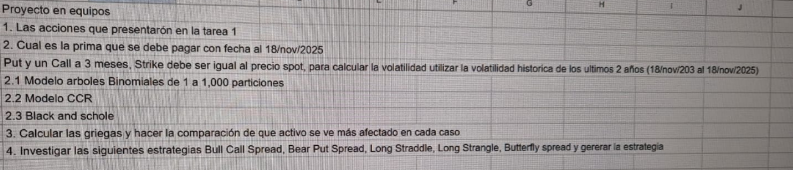

## **Volatilidad Historica**

In [ ]:
# Volatilidad Historica ("Con desviacion")
vol_lista = []

for i in activos:
  media = sum(df_precios[f'rendimientos_{i}']/len(df_precios[f'rendimientos_{i}']))
  vol_sma = np.sqrt(sum((df_precios[f'rendimientos_{i}'])**2)/len(df_precios[f'rendimientos_{i}']))
  vol_lista.append(vol_sma)

vol = pd.DataFrame([vol_lista], columns=[f'vol_hist_{i}' for i in activos])
vol

,vol_hist_DUOL,vol_hist_DNUT,vol_hist_HD,vol_hist_SBUX
0,0.038597,0.042088,0.013521,0.021888


In [ ]:
# Volatilidad Historica (Desviacion Insesgada)
vol_lista = []

for i in activos:
  media = sum(df_precios[f'rendimientos_{i}']/len(df_precios[f'rendimientos_{i}']))
  vol_sma = np.sqrt(sum((df_precios[f'rendimientos_{i}'] - media)**2)/(len(df_precios[f'rendimientos_{i}'])-1))
  vol_lista.append(vol_sma)

vol = pd.DataFrame([vol_lista], columns=[f'vol_hist_{i}' for i in activos])
vol

,vol_hist_DUOL,vol_hist_DNUT,vol_hist_HD,vol_hist_SBUX
0,0.038634,0.042061,0.013531,0.021907


## **Arboles binomiales**

In [ ]:
r = 0.0726 # Rendimineto (Tasa libre de riesgo)
T = 0.25 # Tiempo (3 meses)
pasos = 100 # Intervalo en el que se particiona
K_justo = S0 * np.exp(r * t/1)  # Call = Put , /1 de un año

In [ ]:
a = []

for i in activos:
  S0 = df_precios[f'{i}'].iloc[-1] # Precio Spot
  k = S0 # Precio Strike (Igual a precio Spot)
  vol = vol_lista[activos.index(i)] # Volatilidad
  call = funcion1_opcion(S0,k,vol,r,T,pasos,'call')
  put = funcion1_opcion(S0,k,vol,r,T,pasos,'put')

  a.append([call,put])

resultados = pd.DataFrame(a, columns=['call','put'])
resultados.index = activos
resultados

,call,put
DUOL,3.465149,0.309457
DNUT,0.077366,0.008478
HD,6.015173,0.002041
SBUX,1.516303,0.017506


## **Modelo CRR**

In [ ]:
a = []

for i in activos:
  S0 = df_precios[f'{i}'].iloc[-1] # Precio Spot
  k = S0 # Precio Strike (Igual a precio Spot)
  vol = vol_lista[activos.index(i)] # Volatilidad
  call = funcion2_opcion(S0,k,vol,r,T,pasos,'call')
  put = funcion2_opcion(S0,k,vol,r,T,pasos,'put')

  a.append([call,put])

resultados = pd.DataFrame(a, columns=['call','put'])
resultados.index = activos
resultados



,call,put
DUOL,3.465149,0.309457
DNUT,0.077366,0.008478
HD,6.015173,0.002041
SBUX,1.516303,0.017506


## **Black and Scholes**

In [ ]:
a = []

for i in activos:
  S0 = df_precios[f'{i}'].iloc[-1] # Precio Spot
  k = S0 # Precio Strike (Igual a precio Spot)
  vol = vol_lista[activos.index(i)] # Volatilidad
  call = funcion3_opcion(S0,k,vol,r,T,'call')
  put = funcion3_opcion(S0,k,vol,r,T,'put')

  a.append([call,put])

resultados = pd.DataFrame(a, columns=['call','put'])
resultados.index = activos
resultados



,call,put
DUOL,3.469199,0.313506
DNUT,0.077462,0.008574
HD,6.015647,0.002515
SBUX,1.517153,0.018356


## **Griegas**

In [ ]:
r = 0.0726 # Rendimineto (Tasa libre de riesgo)
T = 0.25 # Tiempo (3 meses)
pasos = 100 # Intervalo en el que se particiona


In [ ]:
a = []

for i in activos:
  S0 = df_precios[f'{i}'].iloc[-1] # Precio Spot
  k = S0 # Precio Strike (Igual a precio Spot)
  vol = vol_lista[activos.index(i)] # Valatilidad

  # Mercado a dia de hoy
  d1 = (np.log(S0/k) + (r+0.5*vol**2)*T)/(vol*np.sqrt(T))
  d2 = d1 - vol * np.sqrt(T)

  # delta
  delta_call = norm.cdf(d1)
  delta_put = -norm.cdf(-d2)

  # vega
  vega_call = S0 * np.sqrt(T) * norm.pdf(d1) # .pdf funcion de probabilidad
  vega_put = S0 * np.sqrt(T) * norm.pdf(d1) # .pdf funcion de probabilidad

  # theta
  theta_call = -S0 * norm.pdf(d1) * vol / (2 * np.sqrt(T)) - r * k * np.exp(-r*T) * norm.cdf(d2)
  theta_put = -S0 * norm.pdf(d1) * vol / (2 * np.sqrt(T)) + r * k * np.exp(-r*T) * norm.cdf(-d2)

  # rho
  rho_call = k * T * np.exp(-r*T) * norm.cdf(d2)
  rho_put = -k * T * np.exp(-r*T) * norm.cdf(-d2)

  # gama
  gama_call = norm.pdf(d1) / (S0 * vol * np.sqrt(T))
  gama_put = norm.pdf(d1) / (S0 * vol * np.sqrt(T))

  a.append([d1,d2,delta_call,delta_put,vega_call,vega_put,theta_call,theta_put,rho_call,rho_put,gama_call,gama_put])

resultados = pd.DataFrame(a, columns=['d1','d2','delta_call','delta_put','vega_call','vega_put','theta_call','theta_put','rho_call','rho_put','gama_call','gama_put'])
resultados.index = activos
resultados

,d1,d2,delta_call,delta_put,vega_call,vega_put,theta_call,theta_put,rho_call,rho_put,gama_call,gama_put
DUOL,0.949254,0.929937,0.828754,-0.176202,22.303125,22.303125,-12.027836,0.480730,35.483934,-7.589642,0.075016,0.075016
DNUT,0.873538,0.852507,0.808815,-0.196966,0.521652,0.521652,-0.263157,0.009900,0.755075,-0.185203,3.381883,3.381883
HD,2.686036,2.679270,0.996385,-0.003689,1.808708,1.808708,-23.795931,0.038982,81.773356,-0.302791,0.004784,0.004784
SBUX,1.662467,1.651514,0.951790,-0.049317,4.173789,4.173789,-5.830829,0.110117,19.448887,-1.008915,0.109749,0.109749


In [ ]:
for i in resultados:
  max = np.abs(resultados[i]).max()

  # Encuentra el activo con el valor absoluto máximo
  max_activo = resultados[np.abs(resultados[i]) == max].index[0]



  print(f'\nColumna: {i} ')
  print(f'Máximo: {max} corresponde al activo {max_activo}')




Columna: d1 
Máximo: 2.6860355729849634 corresponde al activo HD

Columna: d2 
Máximo: 2.6792698817664227 corresponde al activo HD

Columna: delta_call 
Máximo: 0.9963847304877287 corresponde al activo HD

Columna: delta_put 
Máximo: 0.1969662887350025 corresponde al activo DNUT

Columna: vega_call 
Máximo: 22.303124600654936 corresponde al activo DUOL

Columna: vega_put 
Máximo: 22.303124600654936 corresponde al activo DUOL

Columna: theta_call 
Máximo: 23.795931134195218 corresponde al activo HD

Columna: theta_put 
Máximo: 0.480730110366699 corresponde al activo DUOL

Columna: rho_call 
Máximo: 81.77335574034635 corresponde al activo HD

Columna: rho_put 
Máximo: 7.589641792055512 corresponde al activo DUOL

Columna: gama_call 
Máximo: 3.3818832762263034 corresponde al activo DNUT

Columna: gama_put 
Máximo: 3.3818832762263034 corresponde al activo DNUT
